# Generative Adversarial Network (GAN) for Synthetic Image Generation



##Dataset Preparation

In [1]:
#Janani K - 24BAD039

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from IPython.display import clear_output

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Image Dimensions:", x_train.shape[1:])
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Image Dimensions: (28, 28)
Minimum Pixel Value: 0
Maximum Pixel Value: 255


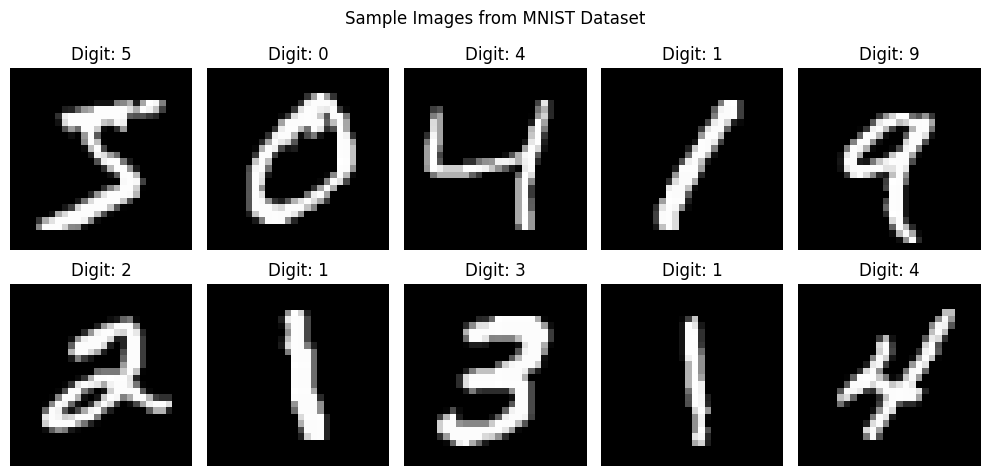

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Digit: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.show()

In [4]:
BUFFER_SIZE = 60000
BATCH_SIZE = 256

# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images to include the channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Normalized Data Shape:", x_train.shape)
print("Minimum Normalized Value:", x_train.min())
print("Maximum Normalized Value:", x_train.max())

# Create batches of real images
train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset preparation completed successfully!")

Normalized Data Shape: (60000, 28, 28, 1)
Minimum Normalized Value: -1.0
Maximum Normalized Value: 1.0
Dataset preparation completed successfully!


### Observations

1. The MNIST dataset was successfully loaded, containing 60,000 training images and 10,000 testing images.
2. Each image has a dimension of 28 × 28 pixels and represents a handwritten digit from 0 to 9.
3. The original pixel values ranged from 0 to 255.
4. The images were normalized to a range of -1 to +1 to make them suitable for GAN training.
5. The training images were reshaped into (60000, 28, 28, 1), and batches were successfully prepared for training.

**Thus, the MNIST dataset was successfully loaded, explored and preprocessed for GAN implementation.**

##IMPLEMENTING THE GENERATOR AND DISCRIMINATOR

In [5]:
#Janani K - 24BAD039

NOISE_DIM = 100
IMAGE_SHAPE = (28, 28, 1)

print("Noise Dimension:", NOISE_DIM)
print("Image Shape:", IMAGE_SHAPE)

Noise Dimension: 100
Image Shape: (28, 28, 1)


In [6]:
def build_generator():

    model = models.Sequential(name="Generator")

    model.add(layers.Input(shape=(NOISE_DIM,)))

    model.add(layers.Dense(7 * 7 * 128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Reshape((7, 7, 128)))

    model.add(layers.Conv2DTranspose(
        64, kernel_size=4, strides=2,
        padding='same', use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(
        1, kernel_size=4, strides=2,
        padding='same', activation='tanh'
    ))

    return model


generator = build_generator()

generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [7]:
def build_discriminator():

    model = models.Sequential(name="Discriminator")

    model.add(layers.Input(shape=IMAGE_SHAPE))

    model.add(layers.Conv2D(
        64, kernel_size=4, strides=2, padding='same'
    ))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(
        128, kernel_size=4, strides=2, padding='same'
    ))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())

    model.add(layers.Dense(1, activation='sigmoid'))

    return model


discriminator = build_discriminator()

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Generate random noise
random_noise = tf.random.normal([1, NOISE_DIM])

# Generate a synthetic image
generated_image = generator(random_noise, training=False)

# Test the Discriminator
prediction = discriminator(generated_image, training=False)

print("Generated Image Shape:", generated_image.shape)
print("Discriminator Prediction:", prediction.numpy())

Generated Image Shape: (1, 28, 28, 1)
Discriminator Prediction: [[0.49846953]]


In [9]:
gan_input = layers.Input(shape=(NOISE_DIM,))

generated_output = generator(gan_input)
gan_output = discriminator(generated_output)

gan = models.Model(
    gan_input,
    gan_output,
    name="Generative_Adversarial_Network"
)

gan.summary()

Model: "Generative_Adversarial_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 910,530 (3.47 MB)

 Non-trainable params: 12,672 (49.50 KB)

### Observations

1. The Generator model was successfully constructed using Dense, Batch Normalization, LeakyReLU and Conv2DTranspose layers.
2. The Generator takes a 100-dimensional random noise vector as input and produces a 28 × 28 grayscale image.
3. The Discriminator was implemented using Conv2D, LeakyReLU, Dropout, Flatten and Dense layers to classify images as real or generated.
4. The Generator contained 784,641 parameters, while the Discriminator contained 138,561 parameters.
5. Both models were successfully combined to form the GAN architecture.
6. The model summaries and initial Generator output were successfully displayed.

**Thus, the Generator, Discriminator and combined GAN architecture were successfully implemented.**

##GAN TRAINING AND PERFORMANCE MONITORING

In [10]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)


def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )


def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [11]:
@tf.function
def train_step(real_images):

    noise = tf.random.normal(
        [BATCH_SIZE, NOISE_DIM]
    )

    # Train Discriminator
    with tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(
            real_images, training=True
        )

        fake_output = discriminator(
            fake_images, training=True
        )

        d_loss = discriminator_loss(
            real_output, fake_output
        )

    disc_gradients = disc_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal(
        [BATCH_SIZE, NOISE_DIM]
    )

    with tf.GradientTape() as gen_tape:

        fake_images = generator(noise, training=True)

        fake_output = discriminator(
            fake_images, training=True
        )

        g_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    return g_loss, d_loss

In [12]:
def generate_and_save_images(model, epoch):

    noise = tf.random.normal([16, NOISE_DIM])

    predictions = model(noise, training=False)

    predictions = (predictions + 1) / 2.0

    plt.figure(figsize=(8, 8))

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle(f"Generated Images - Epoch {epoch}")

    plt.tight_layout()
    plt.show()

Epoch 1/30 | Generator Loss: 0.8695 | Discriminator Loss: 1.0519


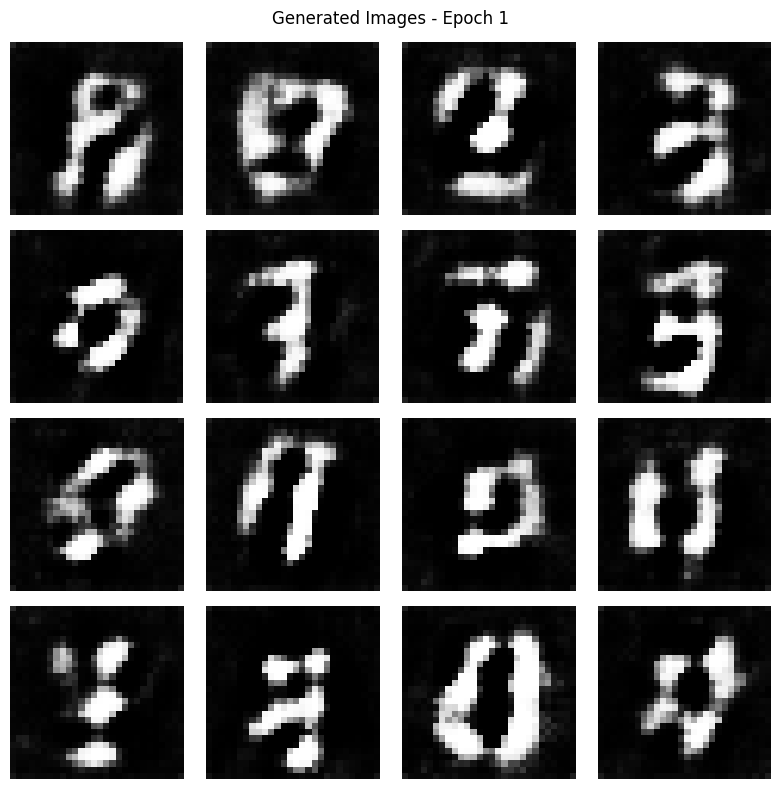

Epoch 2/30 | Generator Loss: 0.8048 | Discriminator Loss: 1.2884
Epoch 3/30 | Generator Loss: 0.8077 | Discriminator Loss: 1.3049
Epoch 4/30 | Generator Loss: 0.8370 | Discriminator Loss: 1.2719
Epoch 5/30 | Generator Loss: 0.8831 | Discriminator Loss: 1.2286


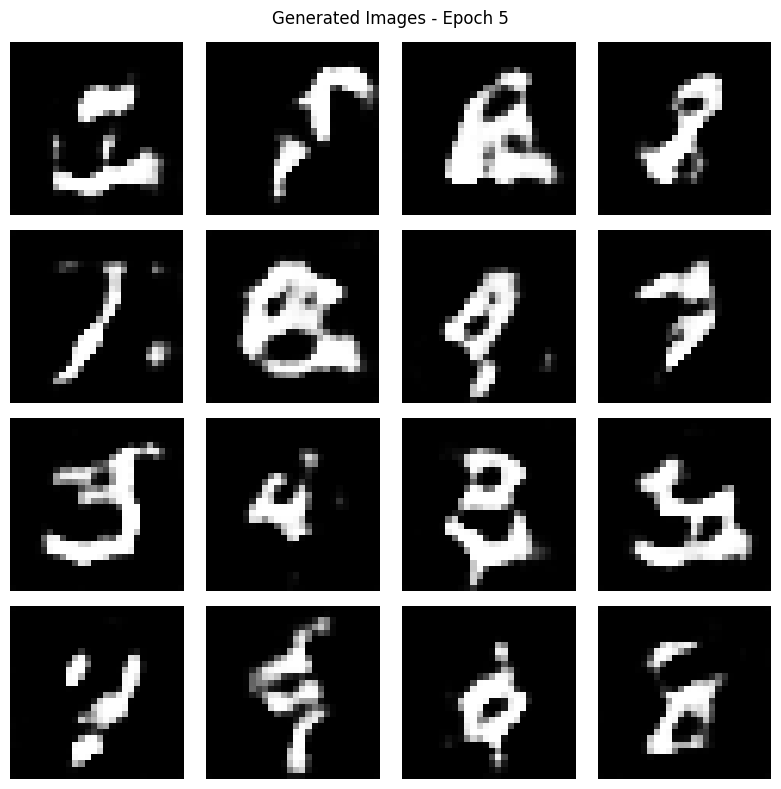

Epoch 6/30 | Generator Loss: 0.8920 | Discriminator Loss: 1.2228
Epoch 7/30 | Generator Loss: 0.8936 | Discriminator Loss: 1.2326
Epoch 8/30 | Generator Loss: 0.8697 | Discriminator Loss: 1.2532
Epoch 9/30 | Generator Loss: 0.8584 | Discriminator Loss: 1.2611
Epoch 10/30 | Generator Loss: 0.8537 | Discriminator Loss: 1.2782


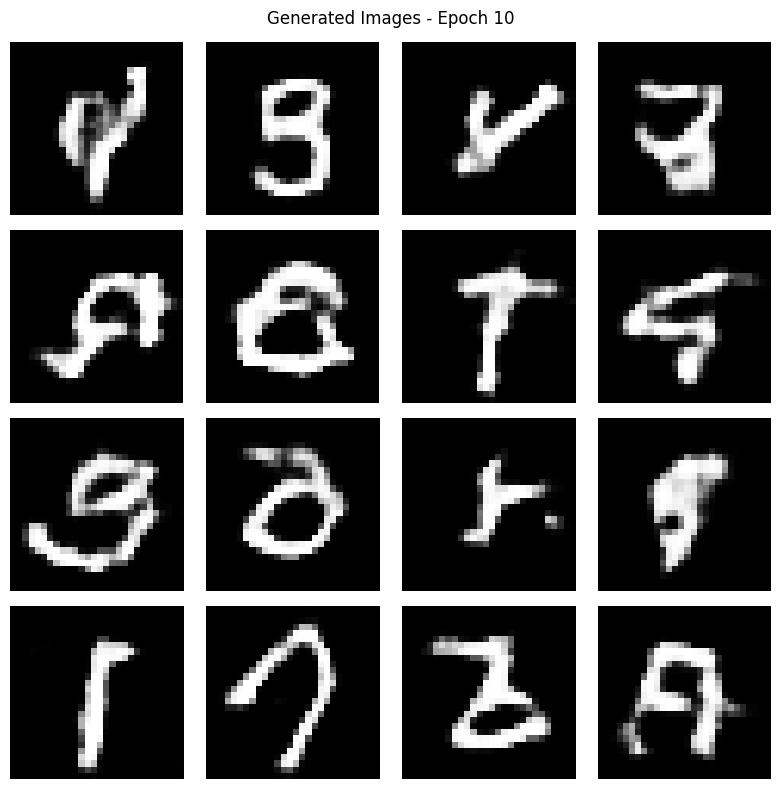

Epoch 11/30 | Generator Loss: 0.8365 | Discriminator Loss: 1.2829
Epoch 12/30 | Generator Loss: 0.8290 | Discriminator Loss: 1.2922
Epoch 13/30 | Generator Loss: 0.8292 | Discriminator Loss: 1.2940
Epoch 14/30 | Generator Loss: 0.8342 | Discriminator Loss: 1.2965
Epoch 15/30 | Generator Loss: 0.8270 | Discriminator Loss: 1.2895


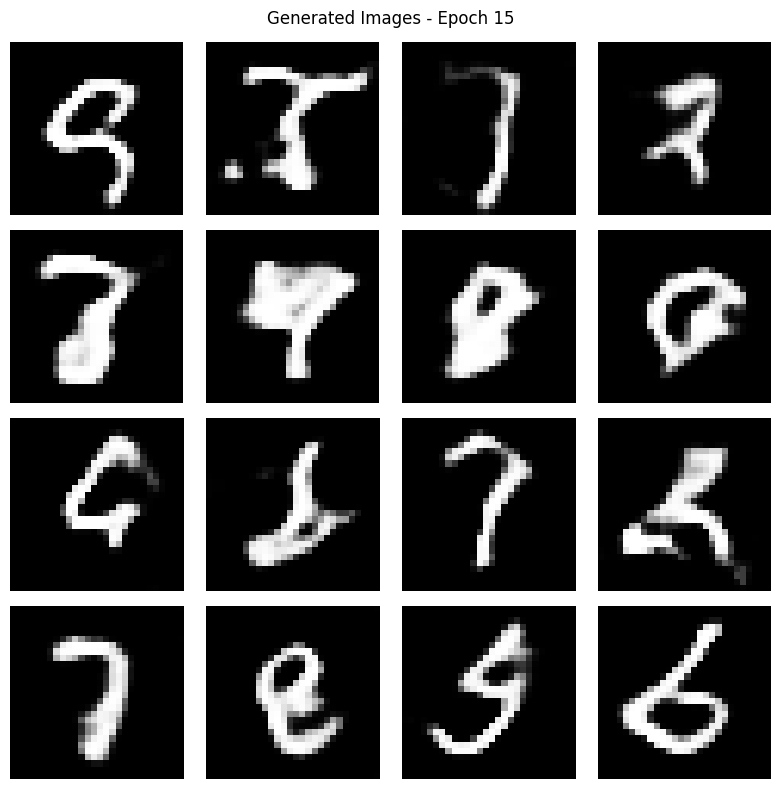

Epoch 16/30 | Generator Loss: 0.8391 | Discriminator Loss: 1.2880
Epoch 17/30 | Generator Loss: 0.8384 | Discriminator Loss: 1.2804
Epoch 18/30 | Generator Loss: 0.8407 | Discriminator Loss: 1.2769
Epoch 19/30 | Generator Loss: 0.8542 | Discriminator Loss: 1.2741
Epoch 20/30 | Generator Loss: 0.8547 | Discriminator Loss: 1.2672


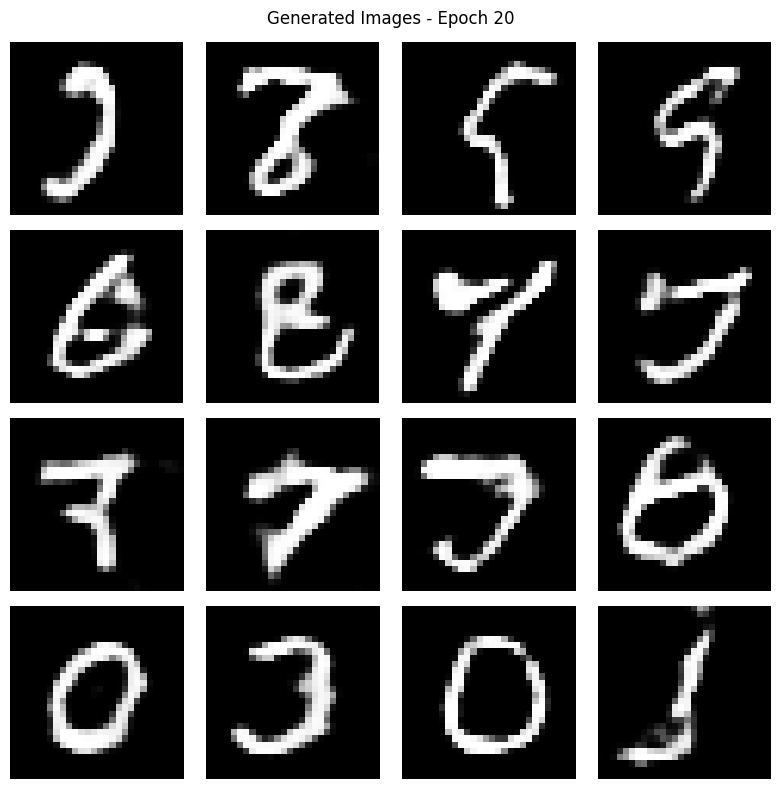

Epoch 21/30 | Generator Loss: 0.8634 | Discriminator Loss: 1.2667
Epoch 22/30 | Generator Loss: 0.8695 | Discriminator Loss: 1.2633
Epoch 23/30 | Generator Loss: 0.8680 | Discriminator Loss: 1.2595
Epoch 24/30 | Generator Loss: 0.8779 | Discriminator Loss: 1.2573
Epoch 25/30 | Generator Loss: 0.8883 | Discriminator Loss: 1.2609


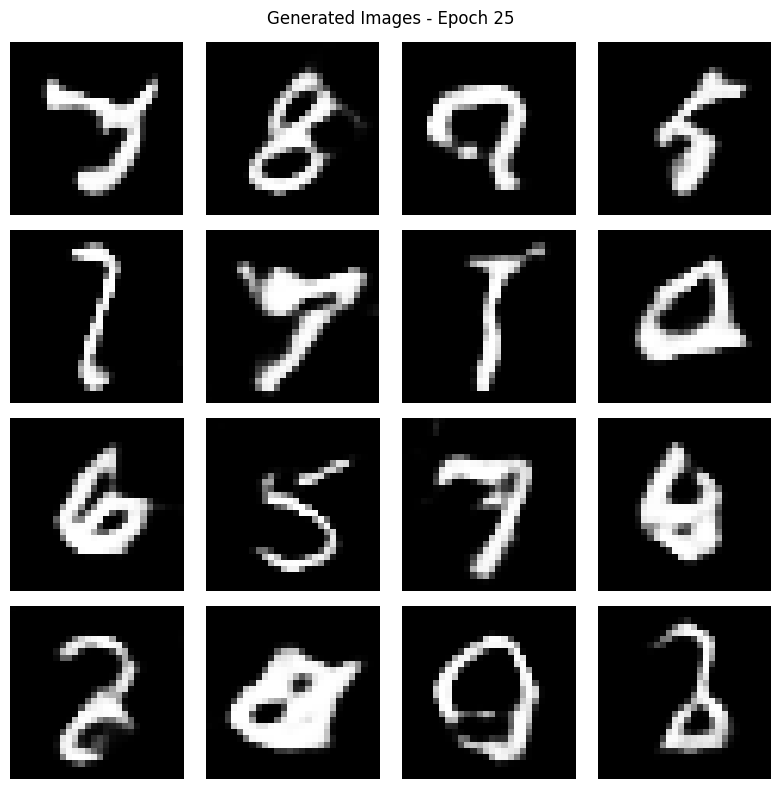

Epoch 26/30 | Generator Loss: 0.8746 | Discriminator Loss: 1.2560
Epoch 27/30 | Generator Loss: 0.8877 | Discriminator Loss: 1.2541
Epoch 28/30 | Generator Loss: 0.8818 | Discriminator Loss: 1.2493
Epoch 29/30 | Generator Loss: 0.8924 | Discriminator Loss: 1.2518
Epoch 30/30 | Generator Loss: 0.8998 | Discriminator Loss: 1.2493


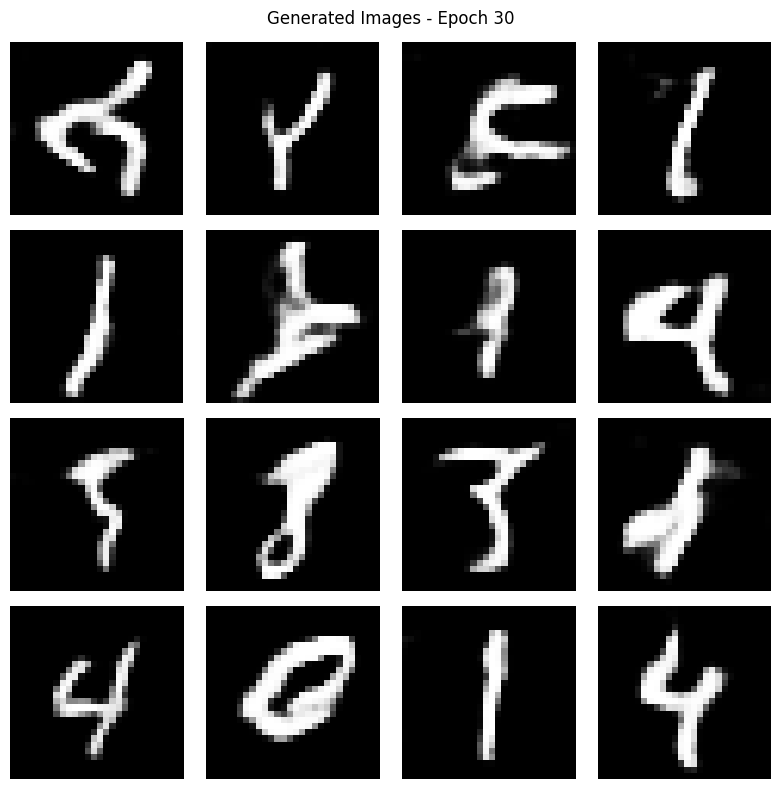

GAN Training Completed Successfully!


In [13]:
EPOCHS = 30

generator_losses = []
discriminator_losses = []

for epoch in range(1, EPOCHS + 1):

    total_g_loss = 0
    total_d_loss = 0
    batches = 0

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        total_g_loss += float(g_loss)
        total_d_loss += float(d_loss)

        batches += 1

    avg_g_loss = total_g_loss / batches
    avg_d_loss = total_d_loss / batches

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator Loss: {avg_g_loss:.4f} | "
        f"Discriminator Loss: {avg_d_loss:.4f}"
    )

    if epoch == 1 or epoch % 5 == 0:
        generate_and_save_images(generator, epoch)

print("GAN Training Completed Successfully!")

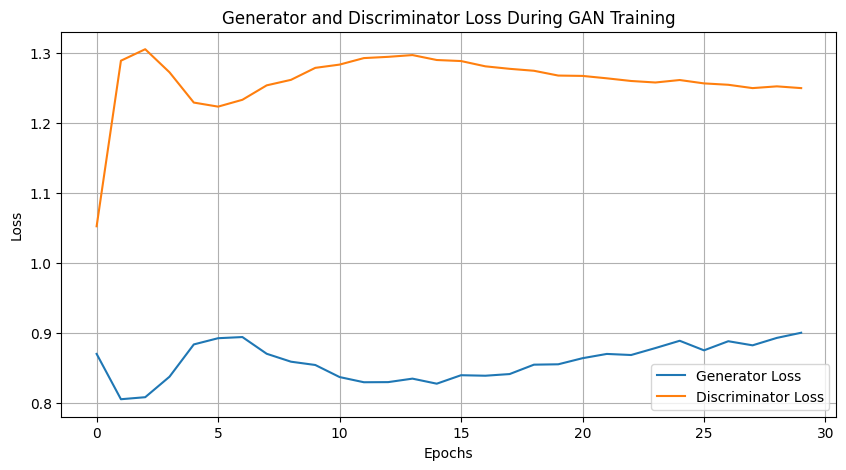

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    discriminator_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss During GAN Training")

plt.legend()
plt.grid(True)
plt.show()

### Observations

1. The GAN was successfully trained for 30 epochs using an adversarial training approach.
2. The Discriminator was trained using both real MNIST images and synthetic images generated by the Generator.
3. The Generator was trained to produce realistic images capable of fooling the Discriminator.
4. Binary Cross-Entropy was used as the loss function, and the Adam optimizer was used for training both networks.
5. The final Generator loss was 0.8998, and the final Discriminator loss was 1.2493.
6. The Generator and Discriminator losses were recorded and visualized using a loss graph.
7. Sample synthetic images were displayed at different stages of training to observe the improvement in image generation.

**Thus, adversarial training was successfully performed, and the performance of both networks was monitored using their loss values.**

##GENERATED IMAGE VISUALIZATION AND EXPERIMENT MANAGEMENT

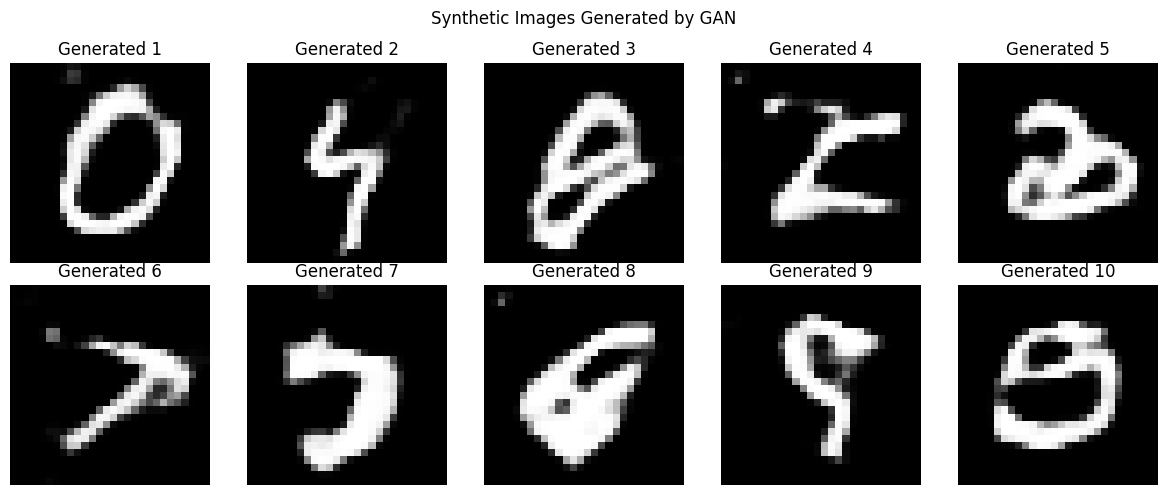

In [15]:
num_images = 10

# Generate random noise vectors
random_noise = tf.random.normal([num_images, NOISE_DIM])

# Generate synthetic images
synthetic_images = generator(
    random_noise, training=False
)

# Convert pixel values from [-1, 1] to [0, 1]
synthetic_images = (synthetic_images + 1) / 2.0

plt.figure(figsize=(12, 5))

for i in range(num_images):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        synthetic_images[i, :, :, 0],
        cmap='gray'
    )

    plt.title(f"Generated {i + 1}")
    plt.axis('off')

plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

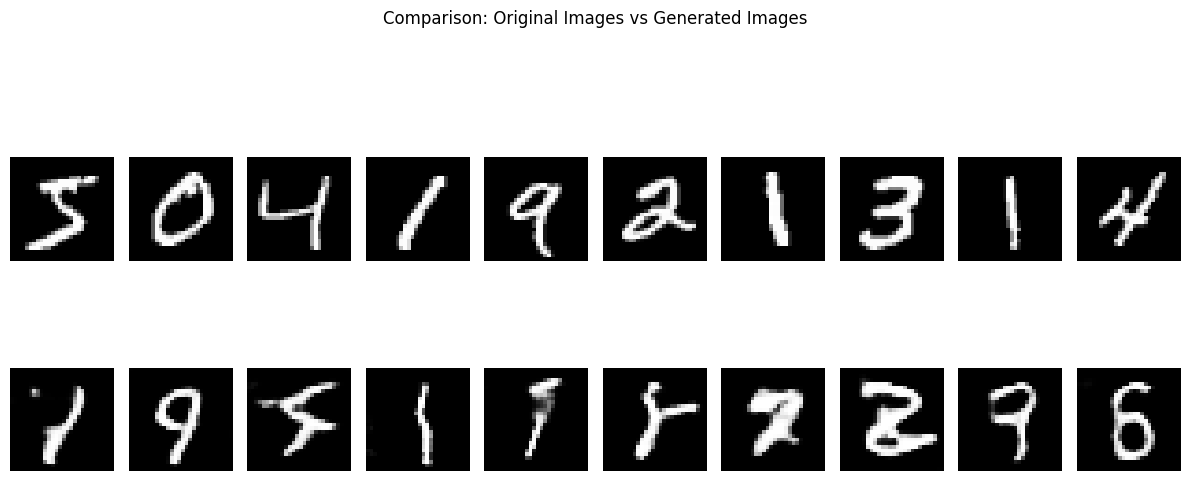

In [16]:
# Select original MNIST images
original_images = x_train[:10]

# Generate 10 synthetic images
noise = tf.random.normal([10, NOISE_DIM])

generated_images = generator(
    noise, training=False
)

# Convert generated images to [0, 1]
generated_images = (generated_images + 1) / 2.0

plt.figure(figsize=(12, 6))

for i in range(10):

    # Original images
    plt.subplot(2, 10, i + 1)

    original_display = (
        original_images[i, :, :, 0] + 1
    ) / 2.0

    plt.imshow(original_display, cmap='gray')
    plt.axis('off')

    # Generated images
    plt.subplot(2, 10, i + 11)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle(
    "Comparison: Original Images vs Generated Images"
)

plt.tight_layout()
plt.show()

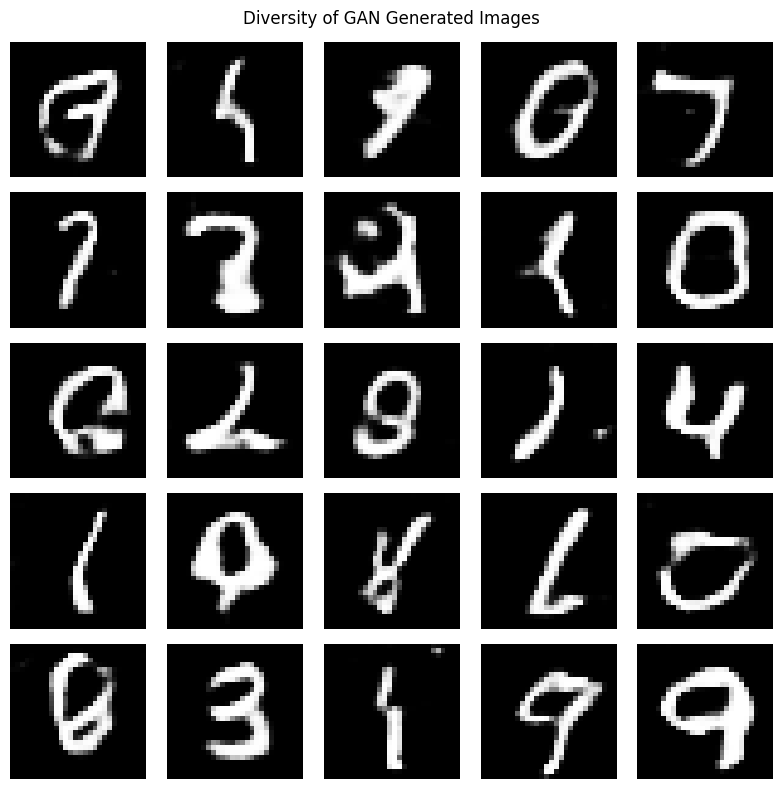

In [17]:
# Generate different images using different noise vectors
noise_vectors = tf.random.normal([25, NOISE_DIM])

diverse_images = generator(
    noise_vectors, training=False
)

diverse_images = (diverse_images + 1) / 2.0

plt.figure(figsize=(8, 8))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(
        diverse_images[i, :, :, 0],
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle("Diversity of GAN Generated Images")
plt.tight_layout()
plt.show()

In [18]:
generator.save("gan_generator.keras")

discriminator.save("gan_discriminator.keras")

print("Generator model saved successfully!")
print("Discriminator model saved successfully!")

Generator model saved successfully!
Discriminator model saved successfully!


In [19]:
from google.colab import files

files.download("gan_generator.keras")
files.download("gan_discriminator.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Observations

1. The trained Generator successfully produced synthetic handwritten digit images using new random noise vectors.
2. The generated images contained recognizable handwritten digit patterns, including digits such as 0, 2, 3, 4, 6, 7 and 9.
3. The generated images were compared with original MNIST images to examine their visual quality and similarity.
4. Different random noise vectors produced different digit patterns, demonstrating diversity in the generated images.
5. Some generated images contained distorted strokes and irregular shapes, indicating that the generated images were not perfectly realistic.
6. The trained Generator and Discriminator models were saved successfully for future use.

**Thus, synthetic image generation, visualization, comparison and experiment management were successfully performed.**